<a href="https://colab.research.google.com/github/Brown-Brayden/econ3916-lab19-random-forests/blob/main/Econ3916_lab19_random_forests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 19: Tree-Based Models — Random Forests
## ECON 3916: Applied Machine Learning for Economists
### Guided Construction Lab | 40 min Core + 55 min AI + 25 min Extension

---

**Learning Objectives:**
- See a single tree memorise its training rows, and a forest of such trees generalise
- Compare a forest with OLS and Ridge on the same split, and read its out-of-bag score
- Compare impurity (MDI) and permutation importance, and explain why they disagree
- Tune `max_depth` and `max_features` by cross-validation
- Write your own prompt for a feature-importance chart, and check the AI's numbers against the lab's

**Dataset:** California Housing (scikit-learn): 20,640 block groups, 8 features, and the median
house value in units of $100,000. You have used it since Lab 4.

**Prerequisites:** the Part 0 sections of Labs 1-5, and the labs before this one. Lab 16's
pipeline with `StandardScaler` and Lab 15's bias-variance curve are used again here.

**How this lab works:** Parts 1-3 are GUIDED: run each cell as it is, then answer the questions.
The AI-Assisted Expansion is required: as in Lab 16, you write the prompt yourself. The Extension
is optional.

**Plan on about 1 hour 55 minutes** for the required work: setup, Parts 1-3, the AI-Assisted
Expansion, and the README and submission.

**AI in the manual parts:** you may ask Colab to *explain* an error or a line of code (click **Explain error**, or select a line and ask Gemini to explain it). Do not ask it to write or fix code, and turn off AI code completion while you work on those parts. AI-assisted coding is allowed only where this lab says so.

---

> ### What you write, and what you run
>
> **You write:**
> - The answers to the interpretation questions, in text cells: two after Part 1, and one each after Parts 2 and 3.
> - **The AI-Assisted Expansion:** your own prompt, from scratch, asking AI for a function that charts a model's feature importances and gives them back as a table; a revised prompt for round 2 (and round 3 if you need it); the AI's reply to each round, as a share link or the text; a short checking log; and two answers. Your prompts, the AI's replies, the log and the answers are what is graded, not the AI's code.
>
> **You run and read:** everything else. Setup and Parts 1-3 are working code to learn from. Read each cell before you run it, and make sure you can say what each line does. The check cells in the AI section: run them; you need not follow their code. The AI's function is pasted, not typed.
>
> **The Extension** (optional) has one guided cell, then a task with no starter code that you write in a new cell. The **README** is text only: the prompt at the end is for documentation, not code.

## Setup

The first line of the setup cell upgrades scikit-learn to 1.9 or later, because the way trees
are built changed in 1.9: with an older version, the tree and forest numbers in this notebook
differ in the third or fourth decimal. The cell prints your scikit-learn version. If it shows a version below 1.9, use **Runtime → Restart session** and run this cell again.

Every model in this lab is given `random_state=RANDOM_STATE`, so running a cell twice gives the
same numbers.

`fetch_california_housing()` downloads the data the first time (a few seconds) and returns it in
parts: `.data` holds the features, `.target` the house values and `.feature_names` the column
names. `pd.DataFrame(data.data, columns=...)` puts the features in a table with those names.
`train_test_split` keeps 20% of the rows (`test_size=0.2`) as test rows, as in Lab 12.

In [1]:
# GUIDED — run as-is
# Step 1: imports, and California Housing split into training and test rows
!pip install "scikit-learn>=1.9" -q

import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f'scikit-learn {sklearn.__version__} (this lab\'s numbers assume 1.9 or later)')
print(f'Training set: {X_train.shape[0]} observations, {X_train.shape[1]} features')
print(f'Test set: {X_test.shape[0]} observations')
print(f'Features: {list(X.columns)}')

# savefig will not create a folder, and a fresh Colab session has no figures/ folder
Path("figures").mkdir(exist_ok=True)

scikit-learn 1.9.1 (this lab's numbers assume 1.9 or later)
Training set: 16512 observations, 8 features
Test set: 4128 observations
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


**Expected output:** 16512 training rows with 8 features, 4128 test rows, and the eight feature
names from `MedInc` (median income, in $10,000s) to `Longitude`.

## Part 1: Decision Tree vs. Random Forest vs. Ridge (GUIDED — 14 min)

We compare four models on the same rows. The question: does the forest's added complexity give
better predictions than simpler alternatives?

Step 2 fits them, each with `.fit(X, y)`, predictors first:
- a **single tree**, `DecisionTreeRegressor`, with no depth limit: it keeps splitting until it
  cannot;
- **OLS**, `LinearRegression`, as in Lab 12;
- **Ridge**, in a pipeline behind `StandardScaler`, as in Lab 16: the penalty falls evenly across
  the features only when they share one scale;
- a **random forest** of 100 trees, `RandomForestRegressor`. Each tree is grown on a bootstrap
  sample of the training rows, so it never sees about a third of them: its *out-of-bag* rows.
  `oob_score=True` asks the forest to score every training row using only the trees that never
  saw it.

Then it scores each model on the training rows and on the test rows. RMSE, the root of the mean
squared error, is in the target's units, $100,000s. The loop collects one dictionary per model,
and `pd.DataFrame(rows).set_index("Model")` turns the list into a table with one row per model.

In [2]:
# GUIDED — run as-is
# Step 2: four models on the same training rows, scored on both sets
tree = DecisionTreeRegressor(random_state=RANDOM_STATE)      # no depth limit
tree.fit(X_train, y_train)

ols = LinearRegression()
ols.fit(X_train, y_train)

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=100, oob_score=True, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

rows = []
for name, model in [('Single Tree', tree), ('OLS', ols),
                    ('Ridge', ridge), ('Random Forest', rf)]:
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Train R²': r2_score(y_train, train_pred),
        'Test R²': r2_score(y_test, test_pred),
    })

results_df = pd.DataFrame(rows).set_index('Model')
print(results_df.round(4))

               Train RMSE  Test RMSE  Train R²  Test R²
Model                                                  
Single Tree        0.0000     0.7030    1.0000   0.6228
OLS                0.7197     0.7456    0.6126   0.5758
Ridge              0.7197     0.7456    0.6126   0.5758
Random Forest      0.1882     0.5060    0.9735   0.8046


**Expected output:**

| Model | Train RMSE | Test RMSE | Train R² | Test R² |
|---|---|---|---|---|
| Single Tree | 0.0000 | 0.7093 | 1.0000 | 0.6161 |
| OLS | 0.7197 | 0.7456 | 0.6126 | 0.5758 |
| Ridge | 0.7197 | 0.7456 | 0.6126 | 0.5758 |
| Random Forest | 0.1882 | 0.5063 | 0.9735 | 0.8044 |

Step 2, continued, looks inside the tree and the forest. `.get_n_leaves()` counts the tree's
final boxes: each leaf is one rectangle of feature space with one prediction, the mean of its
training rows. `rf.max_features` is how many features each split may choose from; `1.0` means
all of them. `.oob_score_` is the out-of-bag R². `results_df.loc[row, column]` reads one cell of
the table. In the prints, `:,` puts commas in the thousands and `:+.6f` shows six decimals with
the sign.

In [3]:
# GUIDED — run as-is
# Step 2, continued: inside the tree and the forest
print(f"single tree: {tree.get_n_leaves():,} leaves for {len(X_train):,} training rows")
print(f"features each split of the forest may choose from: max_features = {rf.max_features}")
print(f"forest out-of-bag R²: {rf.oob_score_:.4f}   "
      f"test R²: {results_df.loc['Random Forest', 'Test R²']:.4f}")

gap = results_df.loc['Ridge', 'Test R²'] - results_df.loc['OLS', 'Test R²']
print(f"Ridge test R² minus OLS test R²: {gap:+.6f}")

single tree: 15,860 leaves for 16,512 training rows
features each split of the forest may choose from: max_features = 1.0
forest out-of-bag R²: 0.8070   test R²: 0.8046
Ridge test R² minus OLS test R²: +0.000028


**Expected output:** 15,870 leaves for 16,512 training rows; `max_features = 1.0`; an
out-of-bag R² of 0.8069 beside a test R² of 0.8044; and Ridge minus OLS of +0.000028.

Three notes on those lines:
- `max_features = 1.0` is the default the lecture asked you to check: `RandomForestRegressor` lets
  every split choose from every feature unless you say otherwise, so Step 2's forest decorrelates
  its trees only through the bootstrap: it is bagging. Part 3 tries the alternatives.
- The out-of-bag R² never touched a test row, yet lands close to the test R²: each training row is
  scored only by the trees that never drew it, so it is a true held-out score. It is not exactly
  the test R² because the rows differ, and each row is scored by only about a third of the trees.
- The penalty gained Ridge essentially nothing here. With 16,512 training rows and only 8
  features, OLS has almost no variance for a penalty to remove; regularization pays when p is
  large relative to n, as in Lab 16 (p = 200, n = 105).

### Interpretation Questions

1. Which model has the largest gap between its train R² and its test R²? Use the leaf count to explain where that gap comes from.
2. The forest's test R² is 0.23 above Ridge's, with the same eight features. What does that say about how the features relate to house values?

*Your answers here:*

1. **The single tree.** Its train R² is 1.0000 and its test R² is 0.6228, a drop of 0.38. The forest drops 0.17 (0.9735 to 0.8046) and OLS only 0.04 (0.6126 to 0.5758). The leaf count shows where the tree's gap comes from. With no depth limit it kept splitting until it had 15,860 leaves for 16,512 training rows, about 1.04 rows per leaf. At most 652 leaves can hold more than one row, so at least 15,208 leaves (96%) hold a single block group. Every training row is predicted by a leaf built around it, which is why the train RMSE is exactly 0.0000: the tree memorized the rows, noise included, rather than fitting a pattern. Since that RMSE is exactly zero, the few shared leaves must hold rows with the same house value. A test row is predicted by whichever one or two training block groups happen to share its box, so the prediction moves with the noise in those few rows. That is variance, and it is the whole gap. The forest's trees are just as deep, but averaging 100 of them, each grown on a different bootstrap sample, cancels much of that noise. Its out-of-bag R² (0.8070) sits beside its test R² (0.8046), so its own 0.9735 on the training rows overstates it in the same way.

2. Ridge does no better than OLS here (+0.000028), and OLS's own train-test gap is only 0.04. So the linear models do not overfit. They underfit, and 0.5758 is the most a straight-line, additive function of these eight columns can do. The forest gets to 0.8046 from the **same** eight columns. The extra 0.23 of test R² is information already in the features that a linear model cannot reach: the features relate to house values through curves, thresholds and interactions. Location is the clearest case. OLS can only fit a tilted plane over latitude and longitude. But a block group's value depends on *where* it is: on the coast or in the Central Valley at the same latitude, in the Bay Area or elsewhere in Northern California. That is an interaction of the two coordinates, and a tree builds it by splitting on one and then the other. Income need not act in a straight line either, and house values are top-coded at $500,001. A line keeps rising past that cap, while a leaf mean cannot. In hedonic-pricing terms, what a characteristic is worth depends on the neighborhood, and the forest finds those local premiums without being told the functional form. This is a statement about prediction: it says the features carry nonlinear predictive information, not what would happen to house values if any one of them changed.

## Part 2: Feature Importance — MDI vs. Permutation (GUIDED — 14 min)

Random forests tell us which features matter most for prediction. But remember: **predictive
importance is not causal importance.** Step 3 measures it two ways, for Step 2's forest.

- **MDI** (mean decrease in impurity), `rf.feature_importances_`, comes free with training. Each
  split lowers the squared error inside its box; MDI adds up those drops for each feature, weighted
  by how many training rows reached the split, and scales them to sum to 1. A split near the root
  reaches most of the training rows, so its drop counts for a lot; a split deep in a tree reaches a
  few rows and counts for little, however much the predictions depend on it.
- **Permutation importance**, `permutation_importance(rf, X_test, y_test, n_repeats=10,
  random_state=RANDOM_STATE)`, uses the fitted forest and the test rows. It shuffles one column
  at a time, which breaks that feature's link with the outcome, and records how far the forest's
  test R² falls (R² is the score `permutation_importance` uses for a regressor unless told
  otherwise). It repeats each shuffle 10 times with different orders, seeded, and
  `.importances_mean` is the average fall.

`pd.Series(values, index=X.columns)` labels each number with its feature. The two Series become
the two columns of one table, sorted by permutation importance, largest first
(`ascending=False`).

In [4]:
# GUIDED — run as-is
# Step 3: impurity (MDI) and permutation importance for Step 2's forest
mdi_importance = pd.Series(rf.feature_importances_, index=X.columns)

perm_result = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE
)
perm_importance = pd.Series(perm_result.importances_mean, index=X.columns)

importance_table = pd.DataFrame({'MDI': mdi_importance, 'permutation': perm_importance})
print(importance_table.sort_values('permutation', ascending=False).round(4))

               MDI  permutation
MedInc      0.5250       0.7329
Latitude    0.0890       0.4427
Longitude   0.0885       0.3361
AveOccup    0.1384       0.2031
HouseAge    0.0546       0.0721
AveRooms    0.0442       0.0277
AveBedrms   0.0297       0.0095
Population  0.0307       0.0080


**Expected output:**

| | MDI | permutation |
|---|---|---|
| MedInc | 0.5250 | 0.7307 |
| Latitude | 0.0889 | 0.4465 |
| Longitude | 0.0886 | 0.3376 |
| AveOccup | 0.1384 | 0.2026 |
| HouseAge | 0.0547 | 0.0726 |
| AveRooms | 0.0442 | 0.0272 |
| AveBedrms | 0.0297 | 0.0091 |
| Population | 0.0306 | 0.0080 |

The AI-Assisted Expansion asks you to reproduce the permutation column with a function written
by AI.

Step 3, continued, draws both columns side by side. A horizontal bar chart (`.plot.barh`) draws
the first row at the bottom, so each Series is sorted smallest first to put the longest bar on
top.

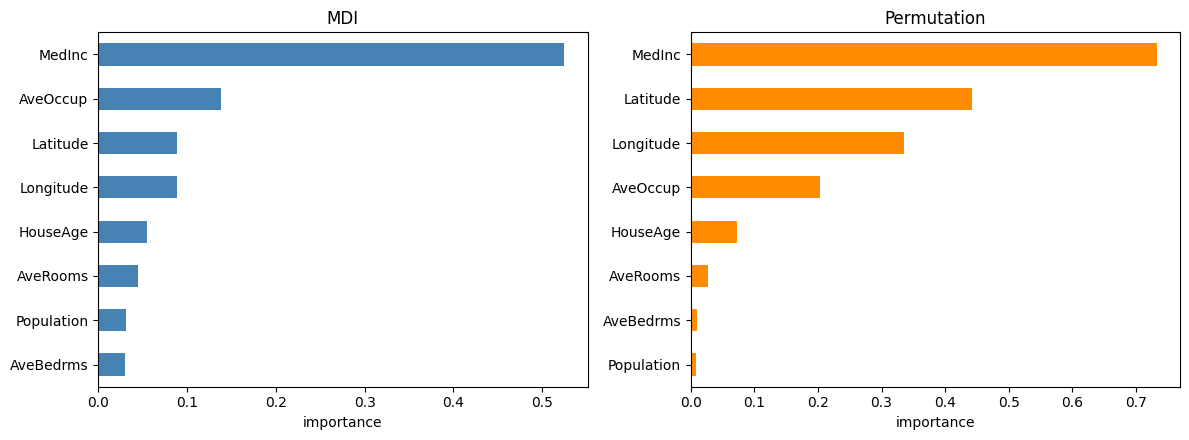

In [5]:
# GUIDED — run as-is
# Step 3, continued: the two measures side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

mdi_importance.sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('MDI')
axes[0].set_xlabel('importance')

perm_importance.sort_values().plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Permutation')
axes[1].set_xlabel('importance')

plt.tight_layout()
plt.savefig('figures/ch19_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretation Questions

1. Compare the two columns by rank, 1st to 8th in each, not by the raw numbers: MDI is scaled to sum to 1 and permutation is a fall in test R², so the two are on different scales. Which features does MDI rank higher than permutation does, and what do they have in common? Which does it rank lower, and why?

*Your answer here:*

My ranks, from Step 3's output:

| Feature | MDI | MDI rank | Permutation | Permutation rank |
|---|---|---|---|---|
| MedInc | 0.5250 | 1 | 0.7329 | 1 |
| AveOccup | 0.1384 | **2** | 0.2031 | **4** |
| Latitude | 0.0890 | **3** | 0.4427 | **2** |
| Longitude | 0.0885 | **4** | 0.3361 | **3** |
| HouseAge | 0.0546 | 5 | 0.0721 | 5 |
| AveRooms | 0.0442 | 6 | 0.0277 | 6 |
| Population | 0.0307 | **7** | 0.0080 | **8** |
| AveBedrms | 0.0297 | **8** | 0.0095 | **7** |

**MDI ranks higher: AveOccup (2nd vs 4th) and Population (7th vs 8th).** Both are head counts: people per household and people per block group. Both are continuous with long right tails, since a handful of block groups have extreme values. They also take a different value in almost every row: AveOccup is a ratio, and Population is a count running into the thousands. Latitude and Longitude are recorded to two decimals, so each has only about a thousand distinct values. A feature like AveOccup or Population offers a split point almost anywhere, and Step 2's trees are fully grown, so deep in each tree these features are handy for separating the last one or two training rows. MDI is computed on each tree's own training (bootstrap) rows and credits every drop in squared error, including drops that only fit noise. So it rewards features that are easy to split on. Permutation importance is measured on test rows, where a split that only fit noise does not help. Population's 0.0080 says shuffling it costs the forest almost nothing out of sample. AveOccup does matter (shuffling it costs 0.20 of test R²). MDI probably still places it ahead of both coordinates because some of its splits sit near the top of the trees, where they reach many rows and count for a lot.

**MDI ranks lower: Latitude (3rd vs 2nd) and Longitude (4th vs 3rd).** Location works through many splits deep in the trees, each carving out a small region, such as a stretch of coast or one metro area. Each of those splits reaches only a few training rows, so MDI weights it little, though the predictions depend on all of them together. The two coordinates also only work as a pair. A cut on latitude alone does not separate San Francisco from the Central Valley, so any one split lowers the error only modestly, and the payoff comes once the other coordinate is split as well. Shuffling Latitude on the test rows moves every block group to a random place on the map at once, and test R² falls by 0.44.

The AveBedrms/Population swap at the bottom is within noise (MDI 0.0297 vs 0.0307, permutation 0.0095 vs 0.0080), and I would not read anything into it. Both measures describe what the forest relies on to predict, not what causes house values.

## Part 3: Hyperparameter Tuning (GUIDED — 12 min)

Step 4 tunes the forest by cross-validation, with `GridSearchCV`. It fits a fresh forest for every
combination in `param_grid`, on every fold, and keeps the combination with the best average score.
- `max_depth`: 10 levels, or `None`, no limit (as in Step 2).
- `max_features`: how many of the 8 features each split may choose from. `'sqrt'` is √8, rounded
  down to 2; `0.5` is half of them, 4. Step 2 used all 8.
- `cv=3`: three folds, as in Lab 15.
- scikit-learn always keeps the *largest* score, so to minimise the error it scores by minus the
  MSE, `'neg_mean_squared_error'`. `np.sqrt(-score)` turns it back into an RMSE.
- `n_jobs=-1` uses every processor core.

Count the work before you run it: 2 × 2 = 4 combinations × 3 folds = 12 forests, each on about
11,000 rows, plus one more to refit the winner on all the training rows: 13. That takes about a
minute on Colab. A 3 × 3 × 3 grid with 5 folds would be 136 forests, and you would still be
waiting when the lab ended.

After the search, `.best_params_` is the winning combination and `.best_score_` its score.
`.best_estimator_` is a forest with those settings, refitted on all the training rows.
`.cv_results_` holds every combination's settings (`'params'`) and average score
(`'mean_test_score'`), in the same order; `zip` walks through the two lists side by side.
`str()` turns `None` into text, and `:<5` left-aligns it in 5 characters, so the columns line up.

In [6]:
# GUIDED — run as-is (about a minute: 13 forests)
# Step 4: tune max_depth and max_features by 3-fold cross-validation
param_grid = {
    'n_estimators': [100],
    'max_depth': [10, None],
    'max_features': ['sqrt', 0.5],
}
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

for params, score in zip(grid_search.cv_results_['params'],
                         grid_search.cv_results_['mean_test_score']):
    print(f"max_depth = {str(params['max_depth']):<5} max_features = "
          f"{str(params['max_features']):<5} CV RMSE {np.sqrt(-score):.4f}")

print(f'\nBest parameters: {grid_search.best_params_}')
print(f'Best CV RMSE: {np.sqrt(-grid_search.best_score_):.4f}')

best_rf = grid_search.best_estimator_
best_pred = best_rf.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, best_pred))
test_r2 = r2_score(y_test, best_pred)
print(f'Tuned RF — Test RMSE: {test_rmse:.4f}, Test R²: {test_r2:.4f}')

max_depth = 10    max_features = sqrt  CV RMSE 0.5525
max_depth = 10    max_features = 0.5   CV RMSE 0.5383
max_depth = None  max_features = sqrt  CV RMSE 0.5068
max_depth = None  max_features = 0.5   CV RMSE 0.5034

Best parameters: {'max_depth': None, 'max_features': 0.5, 'n_estimators': 100}
Best CV RMSE: 0.5034
Tuned RF — Test RMSE: 0.4998, Test R²: 0.8094


**Expected output:** CV RMSEs of 0.5522 (depth 10, `'sqrt'`), 0.5382 (depth 10, 0.5), 0.5066
(no limit, `'sqrt'`) and 0.5048 (no limit, 0.5). Then `Best parameters: {'max_depth': None,
'max_features': 0.5, 'n_estimators': 100}`, `Best CV RMSE: 0.5048`, and
`Tuned RF — Test RMSE: 0.4969, Test R²: 0.8116`.

### Interpretation Questions

1. Within the grid, which setting mattered more? Relative to Step 2's forest, which setting did the tuned forest actually change?

*Your answer here:*

**Within the grid, `max_depth` mattered more.** Removing the depth limit cut the CV RMSE from 0.5525 to 0.5068 with `'sqrt'`, and from 0.5383 to 0.5034 with `0.5`, falls of 0.0457 and 0.0349. Moving `max_features` from `'sqrt'` (2 features per split) to `0.5` (4 features) changed it by only 0.0142 at depth 10 and 0.0034 with no limit. Depth 10 underfits. A tree with at most 2¹⁰ = 1,024 leaves, grown on a fold of about 11,000 rows, averages more than ten bootstrap rows per leaf, which is too coarse for the local location effects from Part 1. A forest works best with deep, low-bias trees, and lets the averaging remove their variance.

**Relative to Step 2's forest, the tuned forest changed only `max_features`.** Step 2 already had `max_depth = None`, and the winner, `{'max_depth': None, 'max_features': 0.5}`, keeps it. The change is that each split now chooses from 4 of the 8 features instead of all 8. Step 2's forest was bagging: every tree could open on MedInc, so the trees were close copies of one another. With 4 of 8, the trees differ more, and averaging trees that are less alike lowers the variance further. On the test rows this took the RMSE from 0.5060 to 0.4998 and R² from 0.8046 to 0.8094. That is a real gain, but a small one. The grid never tried `max_features = 1.0`, so cross-validation itself did not compare the winner with Step 2's setting. Only the test rows do.

---

## AI-Assisted Expansion: a feature-importance chart, your prompt, checked by you

Step 3 took two cells to compute permutation importance and chart it. A function that does both
for any fitted model, and hands back the numbers as a table, is code you would reuse in every
project, and quick for AI to write. It also makes every choice your prompt leaves out, and most of
those choices change the numbers. As in Lab 16, no prompt is given: you write it.

**The target.** Given Step 2's forest and the test rows, your function must reproduce Step 3's
permutation column, all eight features, from **MedInc 0.7307** to **Population 0.0080**. Asked for
the top 3, it must give back MedInc, Latitude and Longitude, in that order, with the same numbers.

**What the check calls.** `importance_chart(model, X, y, k)`: an already fitted `model`, a
DataFrame `X`, the outcome `y`, and `k`, the number of features to keep. It draws a horizontal bar
chart of the top `k` and gives back a pandas DataFrame with columns `feature` and `importance`,
largest first. The check runs it on a copy of Step 2's `rf` with `X_test` and `y_test`, at `k = 8`
and `k = 3`, and counts the forests it fits while it runs (Step 3 fitted none). Then it runs it once
more, at `k = 4`, on a model and rows it has not seen: a tree 6 levels deep, fitted on the training
rows with the columns in reverse order, and the first 500 test rows, beside `permutation_importance`
run on that tree directly. A function that uses the notebook's `rf`, `X_test`, `y_test` or feature
names instead of its own arguments fails there.

**What a good prompt states.** Step 3 and the paragraph above hold every answer.
- the function's name, its arguments in order and their types, and what it gives back;
- the model: what it is, and that it arrives already fitted;
- which importance, and every setting that changes its numbers;
- how the top `k` are picked and sorted;
- the chart: its type, its labels, and which bar goes on top;
- what to leave out (example data, a model of its own), and a comment on each line.

**What to do**
1. Write your round 1 prompt in the cell below and send it, exactly as written, to Claude
   ([claude.northeastern.edu](https://claude.northeastern.edu)) or ChatGPT, in a new chat.
2. Put the AI's reply in the reply cell under your prompt: the chat's share link, or, if your chat
   cannot make one, the whole reply copied in as text. The conversation is graded with your prompt.
3. Read the reply before you run anything. Paste only the function into the round 1 code cell, and
   run the check below it.
4. If a line says `NO`, find the choice in the function that caused it, state that choice in a
   round 2 prompt, and put the reply and the new function in the round 2 cells. A third round goes
   in the round 3 cells under them: new cells, so round 2's function and its check stay in your
   notebook as they ran. Stop when every line says `yes` and you can explain each line, or when
   you decide to stop.
5. If everything says `yes` in round 1, use round 2 to state one choice your prompt never asked
   for, and check that it still matches.
6. Fill in the checking log and answer the two questions. Those, your prompts and the AI's replies
   are graded, not the code.

**Reading the check.** For each `k` it prints Step 3's features in order beside the AI's, then one
line per feature: your number, the AI's, `same?`, and the % apart. Same forest, same rows, same
session: a correct function agrees in every printed digit, whether the rows arrive as a DataFrame
or an array and however many processor cores do the work. There is no allowed gap: a `NO` beside
the same printed digits, with a tiny % apart, means the function rounds its numbers. The last block
compares the function with `permutation_importance` on the other tree (its chart appears too). When every line says `yes`,
the check ends with a line that says so. It does not read the chart: compare its bars with the
table yourself. Each check runs the function twice on all 4,128 test rows, so it takes about as
long as Step 3 twice over: up to a minute on Colab.

Keep the function's name and argument order. If the AI also wrote example data or fitted its own
model, leave that out: it can replace the lab's.

In [7]:
# GUIDED — run as-is (you need not follow this code; the cells below use it)
# The check, as a function: the cells below run it once for each round.
# It saves the forest, the test rows and Step 3's numbers now, before anything is pasted.
import copy
try:
    from sklearn.ensemble._forest import BaseForest     # the class every scikit-learn forest builds on
except ImportError:                                     # if a later release moves it
    BaseForest = RandomForestRegressor

# Step 1's split, rebuilt from the data and the seed: a later cell that reuses the names is caught
_d = fetch_california_housing()
step1_split = train_test_split(pd.DataFrame(_d.data, columns=_d.feature_names), _d.target,
                               test_size=0.2, random_state=RANDOM_STATE)

PROBLEMS = {
    "split": "X_train, X_test, y_train or y_test no longer hold Step 1's split: a cell run after "
             "Step 1 gave those names new data. Usually that is the Extension, if it split with Step 1's "
             "names (it needs its own, such as X_test_c), or pasted code that defined them. Use new "
             "names there, then rerun the notebook from the top (Runtime → Run all).",
    "rf": "rf is no longer Step 2's forest: a cell run after Step 2 gave the name another model, or "
          "refitted it. Usually that is the Extension, if it called its classifier rf (it needs its own "
          "name, such as rf_clf), or pasted code that fitted a model. Use new names there, then rerun "
          "the notebook from the top (Runtime → Run all).",
    "step3": "Step 3's table was made with another forest than the rf you have now. Rerun the notebook "
             "from the top (Runtime → Run all).",
}


def lab_data_problem():
    """None if the split, rf and Step 3's table are still Steps 1-3's; otherwise which one changed."""
    X_tr, X_te, y_tr, y_te = step1_split
    # try runs the lines under it; if they raise an error (say a name is gone), except runs instead
    try:
        if not (X_train.equals(X_tr) and X_test.equals(X_te)
                and np.array_equal(y_train, y_tr) and np.array_equal(y_test, y_te)):
            return "split"
    except Exception:
        return "split"
    try:
        # Step 2's settings, and its out-of-bag score recomputed from Step 1's training outcome
        if not (type(rf) is RandomForestRegressor and rf.n_estimators == 100
                and rf.random_state == RANDOM_STATE and rf.max_features == 1.0
                and np.isclose(r2_score(y_tr, rf.oob_prediction_), rf.oob_score_, rtol=1e-12, atol=0)):
            return "rf"
    except Exception:
        return "rf"
    try:
        if not np.allclose(mdi_importance.values, rf.feature_importances_):
            return "step3"
    except Exception:
        return "step3"
    return None


saved_rf, saved_X, saved_y = rf, X_test.copy(), y_test.copy()
saved_perm = perm_importance.sort_values(ascending=False)     # Step 3's column, largest first

# a model and rows the function has not seen: a 6-level tree on the columns in reverse order
other_cols = list(X_test.columns)[::-1]
other_model = DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE)
other_model.fit(step1_split[0][other_cols], step1_split[2])
other_X, other_y = step1_split[1][other_cols].iloc[:500], step1_split[3][:500]
other_perm = pd.Series(permutation_importance(other_model, other_X, other_y, n_repeats=10,
                                              random_state=RANDOM_STATE).importances_mean,
                       index=other_cols).sort_values(ascending=False)


def show_pair(label, mine, ai):
    """One line: your number, the AI's, whether they agree, and how far apart they are."""
    # rtol=1e-9: equal to about 9 significant digits, so only rounding inside the computer passes
    same = "yes" if np.isclose(mine, ai, rtol=1e-9, atol=0) else "NO"
    pct = 100 * (ai - mine) / abs(mine)
    # a gap under 1%: sign and 2 significant digits, so a tiny one prints like +9.6e-06;
    # otherwise a whole number with its sign, like -200
    apart = f"{pct:+.2g}" if abs(pct) < 1 else f"{pct:+.0f}"
    print(f"  {label:<24}{mine:>10.4f}{ai:>10.4f}{same:>7}{apart:>11}%")
    return same == "yes"


def describe(value):
    """What the function gave back, in a few words."""
    if isinstance(value, (pd.Series, np.ndarray, list, tuple)):
        shown = ", ".join(f"{v:.4f}" if isinstance(v, (int, float, np.number)) else type(v).__name__
                          for v in list(value)[:8])
        return f"a {type(value).__name__}: {shown}"
    return f"a {type(value).__name__}"


def as_table(result):
    """The DataFrame the function gave back, with lower-case column names, or None."""
    if isinstance(result, (tuple, list)):          # (table, chart) or (chart, table)
        tables = [r for r in result if isinstance(r, pd.DataFrame)]
        if tables:
            result = tables[0]
    if not isinstance(result, pd.DataFrame):
        return None
    table = result.rename(columns=lambda c: str(c).lower())
    if "feature" not in table.columns and str(table.index.name).lower() == "feature":
        table = table.reset_index().rename(columns=lambda c: str(c).lower())
    return table


def table_or_message(result, names):
    """The table, or None after saying why the check cannot read what the function gave back."""
    table = as_table(result)
    if table is not None and {"feature", "importance"} <= set(table.columns):
        return table
    if table is not None and "importance" in table.columns and set(map(str, table.index)) <= set(names):
        print("importance_chart gave back a DataFrame with a column named importance, but the feature "
              "names are in its index (the row labels), not in a column of their own.")
    else:
        shown = describe(result) if table is None else f"a DataFrame with columns {list(table.columns)}"
        print(f"importance_chart gave back {shown}.")
    print("The check needs a DataFrame with a column named feature and one named importance.")
    return None


def compare(whose, header, ref, table, k):
    """Print ref's top k beside the AI's rows; give back (every line yes?, a NO beside the same digits?)."""
    ai_names = [str(f) for f in table["feature"]]
    mine_names = list(ref.index[:k])
    print(f"  {whose} top {k}, in order : {', '.join(mine_names)}")
    print(f"  the AI's rows, in order : {', '.join(ai_names)}")
    all_yes = ai_names == mine_names
    print(f"  same features, same order? {'yes' if all_yes else 'NO'}")
    print(f"  {'':<24}{header:>10}{'AI':>10}{'same?':>7}{'% apart':>12}")
    same_digits = False
    for name in mine_names:
        if name not in ai_names:
            print(f"  {name:<24}{ref[name]:>10.4f}{'missing':>10}")
            all_yes = False
            continue
        try:
            ai_value = float(table["importance"][table["feature"].astype(str) == name].iloc[0])
        except Exception:
            print(f"  {name:<24}{ref[name]:>10.4f}   not a number")
            all_yes = False
            continue
        if not show_pair(name, ref[name], ai_value):
            all_yes = False
            same_digits = same_digits or f"{ref[name]:.4f}" == f"{ai_value:.4f}"
    if same_digits:
        print("  A NO beside the same printed digits: the numbers differ only after the 4th decimal. The "
              "usual cause is rounding inside the function (round, .round(4), a format string): give back "
              "the full numbers, and round only when you print.")
    return all_yes


def check_importance_chart(fn):
    """Run the AI's importance_chart on Step 2's forest and the test rows, then on another model."""
    problem = lab_data_problem()
    if problem:
        print(PROBLEMS[problem])
        return
    # callable(x) is True when x is a function that can be called
    if not callable(fn):
        print("importance_chart should be a function. Paste the function the AI wrote.")
        return
    real_fit = BaseForest.fit
    every_line_yes = True
    for k in (8, 3):
        fits = []

        def counting_fit(self, *args, **kwargs):
            fits.append(1)
            return real_fit(self, *args, **kwargs)

        BaseForest.fit = counting_fit        # every forest fitted during the call is counted
        try:
            # a copy of the forest and of the rows, so the function cannot change the lab's
            result = fn(copy.deepcopy(saved_rf), saved_X.copy(), saved_y.copy(), k)
        except Exception as err:
            print(f"With k = {k}, the AI's function stopped with an error. "
                  f"{type(err).__name__}: {err}")
            return
        finally:
            BaseForest.fit = real_fit
        table = table_or_message(result, saved_X.columns)
        if table is None:
            return
        print(f"\nk = {k}")
        every_line_yes &= compare("Step 3's", "Step 3", saved_perm, table, k)
        print(f"  {'forests fitted by it':<24}{0:>10}{len(fits):>10}"
              f"{'yes' if not fits else 'NO':>7}")
        every_line_yes &= not fits

    # once more, on a model and rows it has not seen, beside permutation_importance run directly
    k = 4
    print(f"\nAnother model and other rows, k = {k}: a 6-level tree, the columns in reverse order, "
          f"the first {len(other_X)} test rows")
    try:
        result = fn(copy.deepcopy(other_model), other_X.copy(), other_y.copy(), k)
    except Exception as err:
        print(f"  The AI's function stopped with an error. {type(err).__name__}: {err}")
        print("  It ran on Step 2's forest and the test rows, so look for a line that uses the notebook's "
              "rf, X_test, y_test or feature names instead of the function's own model, X and y.")
        return
    table = table_or_message(result, other_cols)
    if table is None:
        return
    every_line_yes &= compare("the direct run's", "direct", other_perm, table, k)
    try:
        ai = dict(zip(table["feature"].astype(str), table["importance"].astype(float)))
        if len(ai) == k and np.allclose(sorted(ai.values()), sorted(saved_perm.values[:k]), rtol=1e-9, atol=0):
            print("  These are Step 3's numbers, not this tree's: the function uses the notebook's rf, "
                  "X_test or y_test, not the model, X and y it is given.")
        elif (len(ai) == k
              and np.allclose(sorted(ai.values()), sorted(other_perm.values[:k]), rtol=1e-9, atol=0)
              and not all(n in other_perm.index and np.isclose(v, other_perm[n], rtol=1e-9, atol=0)
                          for n, v in ai.items())):
            print("  These are this tree's numbers, beside the wrong names: the function takes the names "
                  "from the notebook (data.feature_names, or X_test's columns), not from the X it is given.")
    except Exception:
        pass
    if every_line_yes:
        print("\nEvery line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest "
              "fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.")
    else:
        print("\nIf a line says NO, find out why before you trust the function.")


problem = lab_data_problem()
if problem:
    print(PROBLEMS[problem])


**Your prompt, round 1.** Write it here, then send it exactly as written.

Sent exactly as written below to Claude (Claude Opus 5.5), in a new chat, on 2026-11-23:

```text
I'm working in a Google Colab notebook for an applied machine learning for economists class (scikit-learn 1.9, pandas, matplotlib). Earlier in the notebook I fit a RandomForestRegressor on the California Housing training rows and computed permutation importance on the test rows by hand, with this call:

permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)

and used .importances_mean as each feature's importance. I want a function I can reuse on any fitted model that gives back exactly those numbers and charts them.

Please write one Python function, importance_chart(model, X, y, k), with the arguments in that order:
- model: a scikit-learn estimator that has ALREADY been fitted. Don't call .fit() on it, and don't fit any other model inside the function.
- X: a pandas DataFrame with the rows to score the model on. Take the feature names from X.columns.
- y: the outcome for those same rows (a NumPy array or a pandas Series).
- k: an int, the number of features to keep.

How to compute the importance: call sklearn.inspection.permutation_importance(model, X, y, n_repeats=10, random_state=42). Leave scoring at its default, which for a regressor is R² (the model's own .score), so each importance is the average fall in R² when that one column is shuffled. Use .importances_mean. Don't set max_samples or sample_weight, and don't round the numbers anywhere in the function.

Top k: sort all the features by importance, largest first, and keep the first k.

What it gives back: a pandas DataFrame with two columns, "feature" (the column name) and "importance" (the full float), one row per kept feature, largest first, index reset to 0, 1, 2, ...

The chart: a horizontal bar chart (matplotlib barh) of those k features, with the largest bar at the top. (barh puts the first row at the bottom, so the plotting order has to be flipped.) Feature names on the y-axis, the x-axis labelled "permutation importance (mean fall in R²)", and a title that says it is the top k. Show it with plt.show(), then return the DataFrame.

Leave out: example data, a demo call, and any model of your own. Use only the four arguments, not variable names from my notebook (no rf, X_test, y_test or hard-coded feature names). Put a short comment on every line saying what it does.
```

**The AI's reply, round 1.** Paste the chat's share link here, or, if your chat cannot make one,
the whole reply copied in as text.

Claude Opus 5.5 (`claude-opus-5-5`), new chat, 2026-11-23. This chat cannot make a share link, so here is the whole reply, copied in as text and unedited:

---

Here's the function. It fits nothing. It only scores the model you pass in, so `importance_chart(rf, X_test, y_test, k)` gives the same `importances_mean` values as your earlier call, provided `rf` and the test rows haven't changed.

```python
import pandas as pd  # build the results table
import matplotlib.pyplot as plt  # draw the bar chart
from sklearn.inspection import permutation_importance  # shuffle-one-column importance


def importance_chart(model, X, y, k):  # top-k permutation importances for an already-fitted model, charted
    result = permutation_importance(model, X, y, n_repeats=10, random_state=42)  # shuffle each column 10 times and record the fall in the default score (R² for a regressor)
    table = pd.DataFrame({"feature": X.columns, "importance": result.importances_mean})  # one row per feature: its name and its mean fall in R²
    table = table.sort_values("importance", ascending=False, kind="stable")  # largest first; tied features keep their original column order
    top = table.head(k).reset_index(drop=True)  # keep the first k rows and renumber the index 0, 1, 2, ...
    plot_order = top.iloc[::-1]  # reverse the rows because barh draws the first row at the bottom
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(top) + 1.5))  # new figure whose height grows with the number of bars
    ax.barh(plot_order["feature"].astype(str), plot_order["importance"])  # one horizontal bar per kept feature, with names on the y-axis
    ax.set_xlabel("permutation importance (mean fall in R²)")  # label the x-axis
    ax.set_title(f"Top {k} features by permutation importance")  # title that names k
    plt.tight_layout()  # stop long feature names from being cut off
    plt.show()  # display the chart
    return top  # DataFrame of the top k features, largest first
```

A few notes:

- **Scoring and rounding:** `scoring` is left at its default, so a regressor is scored with its own `.score`, which is R². `max_samples` and `sample_weight` aren't set, and nothing is rounded.
- **Labels:** `.astype(str)` is used only for the chart labels, so a column name that is a number still shows up as a category. The returned DataFrame keeps the names exactly as they appear in `X.columns`.
- **Ties:** `kind="stable"` only matters if two features have exactly the same importance. In that case they keep their original column order, so the result is the same every run.
- **Large k:** if `k` is more than the number of columns, `head(k)` returns every feature, but the title still says "Top k".

---

In [8]:
# Round 1: the importance_chart function from the AI's round 1 reply, pasted as it wrote it
# (its imports included; it wrote no example data and fitted no model)
import pandas as pd  # build the results table
import matplotlib.pyplot as plt  # draw the bar chart
from sklearn.inspection import permutation_importance  # shuffle-one-column importance


def importance_chart(model, X, y, k):  # top-k permutation importances for an already-fitted model, charted
    result = permutation_importance(model, X, y, n_repeats=10, random_state=42)  # shuffle each column 10 times and record the fall in the default score (R² for a regressor)
    table = pd.DataFrame({"feature": X.columns, "importance": result.importances_mean})  # one row per feature: its name and its mean fall in R²
    table = table.sort_values("importance", ascending=False, kind="stable")  # largest first; tied features keep their original column order
    top = table.head(k).reset_index(drop=True)  # keep the first k rows and renumber the index 0, 1, 2, ...
    plot_order = top.iloc[::-1]  # reverse the rows because barh draws the first row at the bottom
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(top) + 1.5))  # new figure whose height grows with the number of bars
    ax.barh(plot_order["feature"].astype(str), plot_order["importance"])  # one horizontal bar per kept feature, with names on the y-axis
    ax.set_xlabel("permutation importance (mean fall in R²)")  # label the x-axis
    ax.set_title(f"Top {k} features by permutation importance")  # title that names k
    plt.tight_layout()  # stop long feature names from being cut off
    plt.show()  # display the chart
    return top  # DataFrame of the top k features, largest first

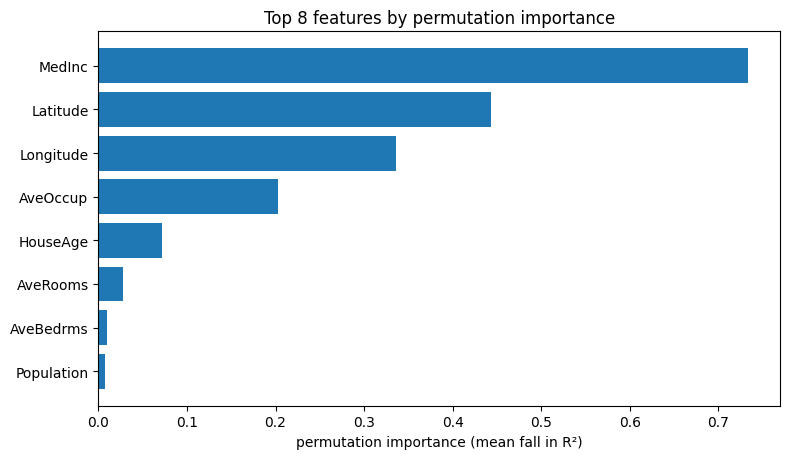


k = 8
  Step 3's top 8, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  the AI's rows, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  AveOccup                    0.2031    0.2031    yes         +0%
  HouseAge                    0.0721    0.0721    yes         +0%
  AveRooms                    0.0277    0.0277    yes         +0%
  AveBedrms                   0.0095    0.0095    yes         +0%
  Population                  0.0080    0.0080    yes         +0%
  forests fitted by it             0         0    yes


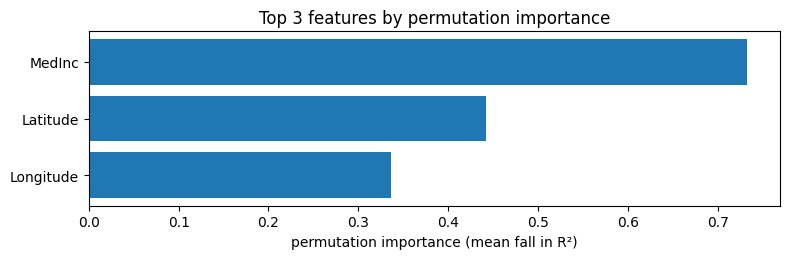


k = 3
  Step 3's top 3, in order : MedInc, Latitude, Longitude
  the AI's rows, in order : MedInc, Latitude, Longitude
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  forests fitted by it             0         0    yes

Another model and other rows, k = 4: a 6-level tree, the columns in reverse order, the first 500 test rows


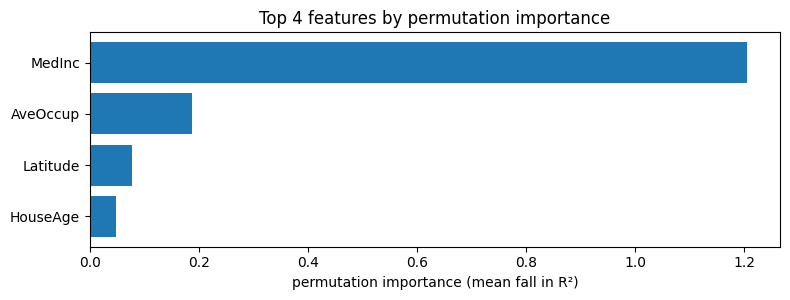

  the direct run's top 4, in order : MedInc, AveOccup, Latitude, HouseAge
  the AI's rows, in order : MedInc, AveOccup, Latitude, HouseAge
  same features, same order? yes
                              direct        AI  same?     % apart
  MedInc                      1.2051    1.2051    yes         +0%
  AveOccup                    0.1866    0.1866    yes         +0%
  Latitude                    0.0774    0.0774    yes         +0%
  HouseAge                    0.0473    0.0473    yes         +0%

Every line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.


In [9]:
# CHECK — round 1
# To rerun this check, rerun the round 1 paste cell first: it checks whatever was pasted last
# globals() holds every name defined so far in this notebook
if "importance_chart" not in globals():
    print("Paste the AI's importance_chart function in the cell above first, keeping that name, "
          "and run that cell.")
else:
    importance_chart_r1 = importance_chart      # kept, so the round 2 check can tell the two apart
    check_importance_chart(importance_chart_r1)

**Your prompt, round 2.** Keep what worked in round 1, and state what the AI had to choose on its
own.

Round 1 passed every line of the check, so, as step 5 says, round 2 states choices my round 1 prompt left to the AI, and checks that the numbers still match. Everything else is round 1 word for word. What I added:
- **`n_jobs=-1`.** Round 1 never said how many processor cores to use, and the AI quietly left `permutation_importance` on its default of one. This is the one unstated setting that could plausibly change the numbers, so I wanted to test it.
- **What to do with a bad `k`.** Round 1's `table.head(k)` quietly hands back the wrong rows for a `k` outside 1 to 8 (see the critique below), so round 2 asks for a `ValueError`.
- **A stable sort.** The AI chose `kind="stable"` on its own in round 1. I kept it, but now it is stated instead of left to chance.

Sent exactly as written below to Claude (Claude Opus 5.5), in a new chat, on 2026-11-23:

```text
I'm working in a Google Colab notebook for an applied machine learning for economists class (scikit-learn 1.9, pandas, matplotlib). Earlier in the notebook I fit a RandomForestRegressor on the California Housing training rows and computed permutation importance on the test rows by hand, with this call:

permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)

and used .importances_mean as each feature's importance. I want a function I can reuse on any fitted model that gives back exactly those numbers and charts them.

Please write one Python function, importance_chart(model, X, y, k), with the arguments in that order:
- model: a scikit-learn estimator that has ALREADY been fitted. Don't call .fit() on it, and don't fit any other model inside the function.
- X: a pandas DataFrame with the rows to score the model on. Take the feature names from X.columns.
- y: the outcome for those same rows (a NumPy array or a pandas Series).
- k: an int, the number of features to keep. If k is less than 1 or more than the number of columns in X, raise a ValueError that says how many columns X has. Don't quietly hand back fewer or different rows (pandas .head() with a negative number drops rows from the end instead of failing).

How to compute the importance: call sklearn.inspection.permutation_importance(model, X, y, n_repeats=10, random_state=42, n_jobs=-1), so the shuffles run on every processor core. As I understand it, each column's shuffles are seeded from random_state however many cores do the work, so n_jobs=-1 should give the same numbers as my one-core call; I'll check that against my own numbers. Leave scoring at its default, which for a regressor is R² (the model's own .score), so each importance is the average fall in R² when that one column is shuffled. Use .importances_mean. Don't set max_samples or sample_weight, and don't round the numbers anywhere in the function.

Top k: sort all the features by importance, largest first, with a stable sort so tied features keep their column order, and keep the first k.

What it gives back: a pandas DataFrame with two columns, "feature" (the column name) and "importance" (the full float), one row per kept feature, largest first, index reset to 0, 1, 2, ...

The chart: a horizontal bar chart (matplotlib barh) of those k features, with the largest bar at the top. (barh puts the first row at the bottom, so the plotting order has to be flipped.) Feature names on the y-axis, the x-axis labelled "permutation importance (mean fall in R²)", and a title that says it is the top k. Show it with plt.show(), then return the DataFrame.

Leave out: example data, a demo call, and any model of your own. Use only the four arguments, not variable names from my notebook (no rf, X_test, y_test or hard-coded feature names). Put a short comment on every line saying what it does.
```

**The AI's reply, round 2.** The share link, or the whole reply as text.

Claude Opus 5.5 (`claude-opus-5-5`), new chat, 2026-11-23. This chat cannot make a share link, so here is the whole reply, copied in as text and unedited:

---

Here's the function. It checks `k` before running the slow permutation step, so a bad `k` fails right away.

```python
import numpy as np  # numerical arrays, used for the bar positions
import pandas as pd  # DataFrame for the returned table
import matplotlib.pyplot as plt  # plotting
from sklearn.inspection import permutation_importance  # scikit-learn's permutation importance routine


def importance_chart(model, X, y, k):  # chart and return the top-k permutation importances of an already-fitted model
    n_cols = X.shape[1]  # number of columns (features) in X
    if k < 1 or k > n_cols:  # reject any k outside 1..n_cols instead of quietly trimming rows
        raise ValueError(f"k must be between 1 and {n_cols}, because X has {n_cols} columns; got k={k}.")  # error says how many columns X has

    perm = permutation_importance(model, X, y, n_repeats=10, random_state=42, n_jobs=-1)  # shuffle each column 10 times on all cores; default scoring = model.score (R² for a regressor)

    table = pd.DataFrame({"feature": X.columns, "importance": perm.importances_mean})  # one row per column, in X's column order, unrounded mean fall in R²
    table = table.sort_values("importance", ascending=False, kind="stable")  # largest first; stable sort keeps tied features in column order
    table = table.iloc[:k].reset_index(drop=True)  # keep the first k rows and renumber the index 0, 1, 2, ...

    positions = np.arange(k)  # one y position per bar, 0 at the bottom
    fig, ax = plt.subplots(figsize=(8, 1.5 + 0.4 * k))  # new figure, taller when there are more bars
    ax.barh(positions, table["importance"].to_numpy()[::-1])  # bars in reversed order so the largest ends up at the top
    ax.set_yticks(positions)  # put one tick at each bar
    ax.set_yticklabels(table["feature"].astype(str).to_numpy()[::-1])  # feature names, reversed to match the bars
    ax.set_xlabel("permutation importance (mean fall in R²)")  # x-axis label
    ax.set_title(f"Top {k} features by permutation importance")  # title that names k
    fig.tight_layout()  # stop long feature names from being cut off
    plt.show()  # display the chart

    return table  # give back the top-k table
```

A few notes:

- **Your `n_jobs=-1` reasoning is right.** `permutation_importance` draws one seed from `random_state` at the start and gives that same seed to every column's job. The shuffles therefore don't depend on how many cores run them, and the numbers should match your one-core call.
- **One possible tiny difference when you compare.** If your forest was built with its own `n_jobs` set (e.g. `RandomForestRegressor(n_jobs=-1)`), it adds up the tree predictions in threads, and the order can change from run to run. That can move the last few decimal places, around 1e-15. If an exact `==` check fails, try `np.allclose`. A difference that small is rounding noise, not different shuffles.
- **How to line the numbers up.** The function returns features sorted by importance, but `.importances_mean` is in column order. To compare, call it with `k` equal to the number of columns and match the rows by feature name, not by position.
- **The y-axis uses positions, not names.** The bars are placed at 0, 1, 2, ... and the feature names are added as labels. So it still works if column names are numbers or repeated, which would confuse `barh` if the names were passed in directly.
- **Nothing is rounded.** Colab shows about 6 decimals when it displays the DataFrame, but the stored floats are full precision.

---

In [10]:
# Round 2: the importance_chart function from the AI's round 2 reply, pasted as it wrote it
# (its imports included; it wrote no example data and fitted no model)
import numpy as np  # numerical arrays, used for the bar positions
import pandas as pd  # DataFrame for the returned table
import matplotlib.pyplot as plt  # plotting
from sklearn.inspection import permutation_importance  # scikit-learn's permutation importance routine


def importance_chart(model, X, y, k):  # chart and return the top-k permutation importances of an already-fitted model
    n_cols = X.shape[1]  # number of columns (features) in X
    if k < 1 or k > n_cols:  # reject any k outside 1..n_cols instead of quietly trimming rows
        raise ValueError(f"k must be between 1 and {n_cols}, because X has {n_cols} columns; got k={k}.")  # error says how many columns X has

    perm = permutation_importance(model, X, y, n_repeats=10, random_state=42, n_jobs=-1)  # shuffle each column 10 times on all cores; default scoring = model.score (R² for a regressor)

    table = pd.DataFrame({"feature": X.columns, "importance": perm.importances_mean})  # one row per column, in X's column order, unrounded mean fall in R²
    table = table.sort_values("importance", ascending=False, kind="stable")  # largest first; stable sort keeps tied features in column order
    table = table.iloc[:k].reset_index(drop=True)  # keep the first k rows and renumber the index 0, 1, 2, ...

    positions = np.arange(k)  # one y position per bar, 0 at the bottom
    fig, ax = plt.subplots(figsize=(8, 1.5 + 0.4 * k))  # new figure, taller when there are more bars
    ax.barh(positions, table["importance"].to_numpy()[::-1])  # bars in reversed order so the largest ends up at the top
    ax.set_yticks(positions)  # put one tick at each bar
    ax.set_yticklabels(table["feature"].astype(str).to_numpy()[::-1])  # feature names, reversed to match the bars
    ax.set_xlabel("permutation importance (mean fall in R²)")  # x-axis label
    ax.set_title(f"Top {k} features by permutation importance")  # title that names k
    fig.tight_layout()  # stop long feature names from being cut off
    plt.show()  # display the chart

    return table  # give back the top-k table

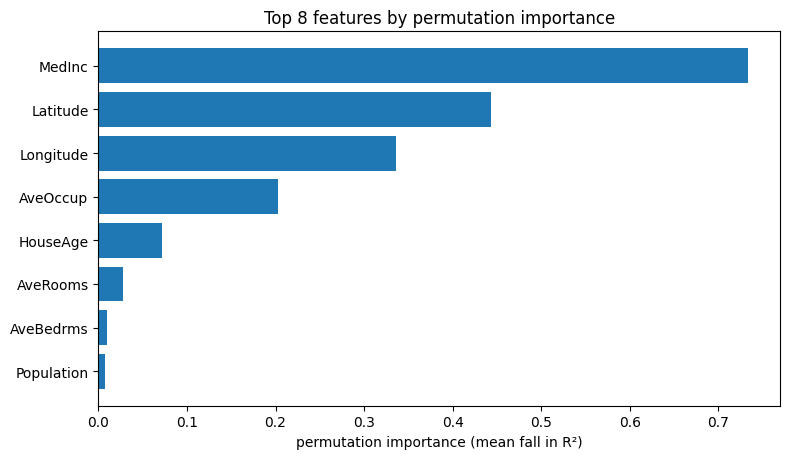


k = 8
  Step 3's top 8, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  the AI's rows, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  AveOccup                    0.2031    0.2031    yes         +0%
  HouseAge                    0.0721    0.0721    yes         +0%
  AveRooms                    0.0277    0.0277    yes         +0%
  AveBedrms                   0.0095    0.0095    yes         +0%
  Population                  0.0080    0.0080    yes         +0%
  forests fitted by it             0         0    yes


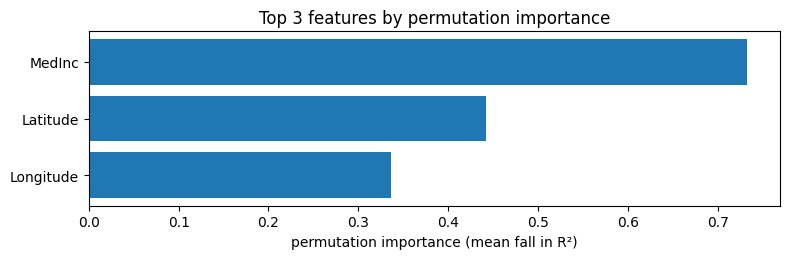


k = 3
  Step 3's top 3, in order : MedInc, Latitude, Longitude
  the AI's rows, in order : MedInc, Latitude, Longitude
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  forests fitted by it             0         0    yes

Another model and other rows, k = 4: a 6-level tree, the columns in reverse order, the first 500 test rows


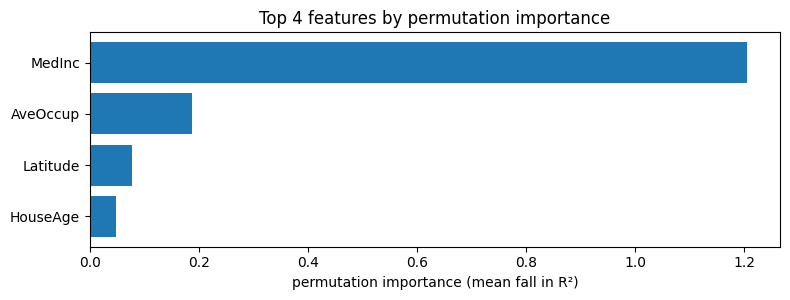

  the direct run's top 4, in order : MedInc, AveOccup, Latitude, HouseAge
  the AI's rows, in order : MedInc, AveOccup, Latitude, HouseAge
  same features, same order? yes
                              direct        AI  same?     % apart
  MedInc                      1.2051    1.2051    yes         +0%
  AveOccup                    0.1866    0.1866    yes         +0%
  Latitude                    0.0774    0.0774    yes         +0%
  HouseAge                    0.0473    0.0473    yes         +0%

Every line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.


In [11]:
# CHECK — round 2
# To rerun this check, rerun the round 2 paste cell first: it checks whatever was pasted last
# "is" asks whether two names hold the very same function: if so, nothing new was pasted
if "importance_chart" not in globals() or importance_chart is globals().get("importance_chart_r1"):
    print("Paste the AI's round 2 importance_chart function in the cell above first, "
          "keeping that name, and run that cell.")
else:
    importance_chart_r2 = importance_chart      # kept, so the round 3 check can tell the two apart
    check_importance_chart(importance_chart_r2)

**Round 3, only if you need one.** These are new cells, so round 2's function and its check stay
in your notebook as they ran. Write the round 3 prompt here, with the share link or the reply under it,
then paste the function in the code cell below and run the check under that. If you stopped at round 2,
write "No round 3" here and leave the two code cells as they are.

**No round 3.** Round 2 passed every line of the check, and I can explain every line of its function, so I stopped there.

In [12]:
# Round 3 only: paste the importance_chart function from round 3 here, then run the check below.
# Paste only the function: if the AI also wrote example data or fitted a model, leave it out.

In [13]:
# CHECK — round 3 (only if you need one)
# To rerun this check, rerun the round 3 paste cell first: it checks whatever was pasted last
if "importance_chart" not in globals() or any(
        importance_chart is globals().get(name) for name in ("importance_chart_r1", "importance_chart_r2")):
    print("No round 3 function pasted. If you stopped at round 2, leave this cell as it is; otherwise "
          "paste round 3's importance_chart in the cell above, keeping that name, and run that cell.")
else:
    check_importance_chart(importance_chart)

No round 3 function pasted. If you stopped at round 2, leave this cell as it is; otherwise paste round 3's importance_chart in the cell above, keeping that name, and run that cell.


### Checking log

This is graded, with your prompts, the AI's replies and the two answers below. One row per round:
what you checked, how you checked it, and what you found. A row that names the line that differed,
how far apart it was, and the line of the AI's code responsible earns credit; "it worked" does not.
If every line of a round said `yes`, no line differed: name instead the line of the AI's code that
computes the importances, and compare it with Step 3's call yourself, setting by setting (the rows,
the score, the repeats, the seed), saying what you found. The last row is the chart, which the check
does not read: compare its bars with the table of your final round.

| Round | What I checked | How | What I found |
|---|---|---|---|
| 1 | Does the function reproduce Step 3's permutation column (names, order, every number) at k = 8 and k = 3? Does it fit no forest? Does it use its own arguments on the other tree at k = 4? | Ran the round 1 check cell. Since no line differed, I then read the AI's importance line against Step 3's call, setting by setting. | Every line said yes: all 8 features in Step 3's order with the same numbers at k = 8 (MedInc 0.7329 down to Population 0.0080), MedInc, Latitude and Longitude at k = 3, 0 forests fitted, and the other tree's numbers under the right names at k = 4. The line that computes them is `result = permutation_importance(model, X, y, n_repeats=10, random_state=42)`. Against Step 3's `permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE)`: **rows**: the check passes copies of `X_test` and `y_test`, all 4,128 rows (`max_samples` left at 1.0 in both); **score**: neither sets `scoring`, so both use the forest's own `.score`, R²; **repeats**: 10 in both; **seed**: 42, which is `RANDOM_STATE`; **cores**: the default, one, in both. Nothing is rounded: `result.importances_mean` goes into the table as it is. (My Step 3 gives MedInc 0.7329, not the lab's 0.7307, because Colab installed scikit-learn 1.9.1. The check compares with my own Step 3.) |
| 2 | The same three blocks, after adding `n_jobs=-1`, a stable sort and a check on `k`. Does `n_jobs=-1` change any number? | Ran the round 2 check cell, and compared round 2's importance line with round 1's and with Step 3's. | Every line said yes again, so `n_jobs=-1` moved no number, not even past the 9th significant digit the check compares. The line is now `perm = permutation_importance(model, X, y, n_repeats=10, random_state=42, n_jobs=-1)`, which differs from Step 3's call only in `n_jobs`. `permutation_importance` draws one seed from `random_state=42` and gives that same seed to every column's job, so the cores divide up the columns, not the shuffles. The new `if k < 1 or k > n_cols: raise ValueError(...)` lets the check's k = 8, 3 and 4 through. |
| 3 (if any) | None | None | No round 3: round 2 passed every line. |
| Chart | Round 2's charts against its tables: k = 8 and k = 3 on Step 2's forest, and k = 4 on the other tree. | Looked at each chart beside the numbers the check printed for it. | All three charts match their tables. **k = 8:** eight bars with the longest on top, in the table's order (MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population). The bars end at the printed values: MedInc about 0.73, Latitude 0.44, Longitude 0.34, AveOccup 0.20, HouseAge 0.07, AveRooms 0.03, and AveBedrms and Population barely visible near 0.01. **k = 3:** only MedInc, Latitude and Longitude, with the same lengths. **k = 4, the other tree:** MedInc, AveOccup, Latitude, HouseAge, as in its table, but MedInc's bar runs past 1.2 (1.2051), which looked wrong at first. A fall in R² bigger than 1 means the shuffled R² went below zero: with MedInc scrambled, the 6-level tree, which leans on it far more than on anything else, predicts worse than the mean would. The titles say Top 8, Top 3 and Top 4. The x-axis label is 'permutation importance (mean fall in R²)', and the feature names are on the y-axis. |

### Questions

1. **Critique, in your own words.** Name one choice the AI made that your prompt never stated, quote the line where it makes it, and say whether you would keep it and why. (A choice that caused a `NO` counts. If everything said `yes`, name a line that would give wrong numbers or break on another model or data instead: for example a classifier, whose default score is accuracy, not R²; `X` as a NumPy array; a hard-coded seed.) Then quote the lines of your final function that compute the importances and the lines that sort them and keep the top `k`, and explain in 2-3 sentences, in your own words, what they do and why they give Step 3's numbers.
2. **Judgment: where you stopped.** Which round did you stop at, and why do you, or do you not, trust that function on a model and data the check has never seen? Then: when would you ask AI to write chart code like this, and when would you write it yourself?

*Your answers here:*

1. **A choice my prompt never stated.** My round 1 prompt said how to sort and keep the top k, but not what to do when k is out of range. The AI decided that in this line:

   `top = table.head(k).reset_index(drop=True)  # keep the first k rows and renumber the index 0, 1, 2, ...`

   I would not keep it. For any k from 1 to 8 it is right, but `.head()` never complains. `importance_chart(rf, X_test, y_test, -1)` would quietly give back the top 7 features under the title "Top -1 features", because a negative number tells `.head()` to drop rows from the end. `k = 20` would give back all 8 rows under "Top 20". Either way a wrong table comes back with no error. The AI's reply even mentioned the large-k case but did not guard against it. So round 2 asked for a `ValueError`, and the AI put `if k < 1 or k > n_cols: raise ValueError(...)` before the slow permutation step, so a bad k fails at once.

   **The lines of my final (round 2) function that compute the importances:**
   ```python
   perm = permutation_importance(model, X, y, n_repeats=10, random_state=42, n_jobs=-1)
   table = pd.DataFrame({"feature": X.columns, "importance": perm.importances_mean})
   ```
   **The lines that sort them and keep the top k:**
   ```python
   table = table.sort_values("importance", ascending=False, kind="stable")
   table = table.iloc[:k].reset_index(drop=True)
   ```
   The first line shuffles each column of the rows it is given 10 times and records how far the model's own score (R² for a regressor) falls each time. The second pairs each column's average fall with that column's name from `X`. Step 3 called the same function with the same forest, the same 4,128 test rows, the same default score, 10 repeats and seed 42. `n_jobs=-1` only spreads the columns across cores without changing the shuffles, so the averages are Step 3's numbers exactly, not just to four decimals. The last two lines put them in descending order and keep the first k rows, renumbered from 0. That is why k = 3 gives back MedInc, Latitude and Longitude in Step 3's order.

2. **I stopped at round 2.** Both rounds passed every line, round 2 changed only what I asked it to, and I can say what each of its lines does. A third round would have had nothing to fix.

   **Do I trust it on a model and data the check has never seen?** For any fitted regressor, given a DataFrame of held-out rows, yes. The function does nothing of its own to the numbers: it passes its `model`, `X` and `y` straight to `permutation_importance` with fixed settings. The check's last block shows it really uses those arguments and not my notebook's names: a different model, the columns in a different order, and 500 other rows all came through correctly. But there are three cases where I would not trust it blindly, and all three come from my own prompt:
   - **A classifier.** Its default score is accuracy, so the numbers would be falls in accuracy, but the x-axis label I asked for still says "mean fall in R²". The label would be wrong, and the numbers would not be comparable with a regressor's.
   - **`X` as a NumPy array.** I asked for the names from `X.columns`, and an array has no `.columns`, so the function stops with an error. At least it fails loudly.
   - **The hard-coded seed.** `random_state=42` means every call uses the same shuffles. That is what made it match Step 3. But I cannot see how much the ranking moves under a different seed, which matters on small data, without editing the function.

   It also measures importance on whatever rows it is handed. It only tells me what the model needs *out of sample* if I pass it test rows, not training rows.

   **When I would use AI, and when I would write it myself.** I would ask AI for wrapper and chart code like this. It is plumbing whose every setting I can state, and whose output I can check against a number I already have. Here the AI got the fiddly parts right without being told: a figure that grows with k, bar positions that still work if column names repeat, a stable sort. That saved typing, not thinking. The line that decides the numbers I would write myself, or at least dictate setting by setting as I did here: which importance, which rows, which score, which seed. Those choices *are* the analysis, and a wrong default there gives believable numbers with no error. If I had no Step 3 to check against, I would write the function myself first and then compare the AI's with it.

---

## Extension (Optional — 25 min): Partial Dependence Plots, and a Forest as a Classifier

**Partial dependence.** A partial dependence plot shows how the forest's prediction moves with one
feature, averaging over the values of all the others in the test rows. It shows the shape of a
relationship the forest found, curves and flat stretches included, which one OLS coefficient
cannot. Step 5 draws it for the tuned forest of Step 4, for `MedInc` and `AveOccup`
(`kind='average'`: the average curve only). Like importance, it describes the model, not a cause.

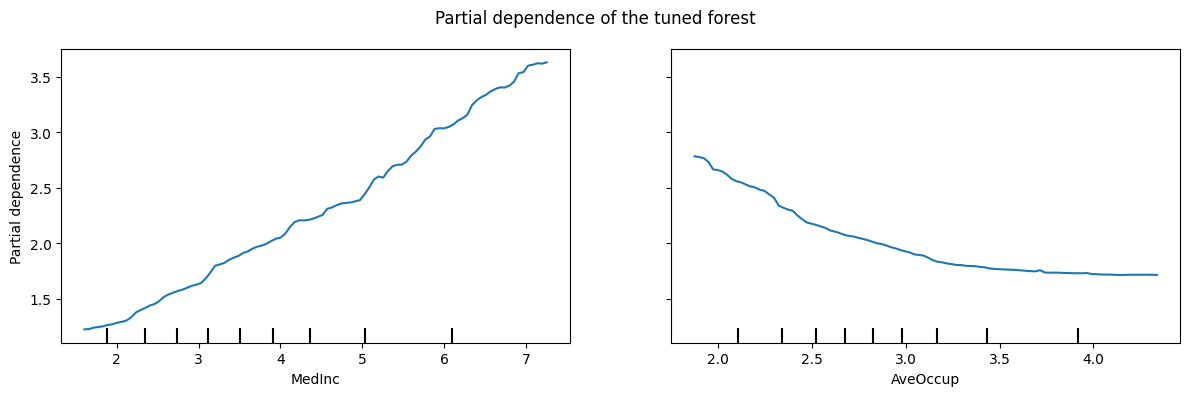

In [14]:
# GUIDED — run as-is (optional)
# Step 5: partial dependence of the tuned forest on two features
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    best_rf, X_test, features=['MedInc', 'AveOccup'], kind='average', ax=ax
)
plt.suptitle('Partial dependence of the tuned forest')
plt.tight_layout()
plt.savefig('figures/ch19_partial_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

**A forest as a classifier.** There is no starter code: write it in the cell below.

Turn the house value into a yes/no outcome, 1 when `y` is above its median (`np.median(y)`) and 0
otherwise (`.astype(int)` turns True/False into 1/0). Split it as Step 1 did (`test_size=0.2`,
`random_state=RANDOM_STATE`), with new names: `X_train_c`, `X_test_c`, `y_train_c` and `y_test_c`, and
`rf_clf` for the forest. `X_train`, `X_test`, `y_train`, `y_test` and `rf` must keep Step 1's and Step
2's meaning, because Steps 2-5 and the AI check read them: a check run after this cell would refuse
them. Fit `RandomForestClassifier(n_estimators=200,
random_state=RANDOM_STATE)` and, for comparison, Lab 17's logistic regression with the features
scaled first: `make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))`. Score each on the test rows by AUC, from Lab 18:
`roc_auc_score(y_true, scores)`, where the scores are `.predict_proba(X)[:, 1]`. Import the three
from `sklearn.ensemble`, `sklearn.linear_model` and `sklearn.metrics`. With these settings the
forest scores 0.9609 and the logistic regression 0.9082. Without the scaler, `LogisticRegression`
does not converge in 1,000 iterations on these features, which is why Lab 17 scaled them first.

**Your answers.** Does the forest beat logistic regression on AUC, and is the difference
practically significant? If you were building this for a real estate company, which would you
choose, and why? Consider accuracy, interpretability and the cost of keeping it running.

If you skip this task, leave its cell unrun, so your submitted notebook shows no error.

In [15]:
# EXTENSION (optional) — write your classification comparison here

*Skipped.* The Extension is optional. Step 5 runs as given, and the classification cell above is left with only its comment, as the lab says, so the notebook shows no error.

---
## Digital Portfolio: Your README

Copy the prompt below into Claude or ChatGPT. Fill in each [YOUR VALUE] from your own output
first, and do not quote a number this notebook did not print. **Do NOT ask the AI to write
Python code — only documentation.**

```
I need help writing a project README for my data science lab.
**Important Rule:** Do NOT generate any Python code for me.

**What I did in this lab:**
* Compared a single decision tree, OLS, Ridge and a random forest on
  California Housing: test R² [YOUR VALUE] for the tree, [YOUR VALUE]
  for Ridge and [YOUR VALUE] for the forest
* Compared impurity (MDI) and permutation importance: Latitude scored
  [YOUR VALUE] by MDI but [YOUR VALUE] by permutation
* Tuned the forest by cross-validation: test R² [YOUR VALUE]
* Wrote my own prompt asking an AI for a feature-importance chart, went
  [YOUR VALUE] rounds, and checked it against my numbers: [YOUR RESULT]

**Please write a README.md entry including:**
1. Project Title: Tree-Based Models: Random Forests
2. Objective: one sentence
3. Methodology: Bullet points of technical steps
4. Key Findings: Summary of results
Write it plainly, in the first person. No words like 'robust', 'comprehensive'
or 'leverage'. Use only the numbers I gave you.
```

---

## Submit this lab on GitHub

**Repository name for this lab:** `econ3916-lab19-random-forests`

**First time?** Read the **GitHub Setup** page in the Start Here module once,
start to finish. It assumes you have never used git and never seen GitHub.

1. On [github.com](https://github.com): **+** (top right) → **New repository**.
   Name it exactly `econ3916-lab19-random-forests`, tick **Add a README file**, and create it.
2. In Colab: **File → Save a copy in GitHub**. Choose `econ3916-lab19-random-forests`, branch `main`,
   commit message `Lab 19 submission`. This pushes the notebook, and the
   notebook's rendered output — charts included — is what is graded.
3. Open the repo on github.com, click `README.md`, then the pencil icon, and
   paste in the README you drafted from the prompt above. **Commit
   changes.** Check every number in it against your own output first: this
   goes out under your name.
4. On Canvas: in Colab use **File → Download → Download .ipynb**, upload that
   file to the assignment, and paste your repository URL in the **Comments**
   box beside the upload. Then click **Submit**. Do not use the Website URL
   tab: Canvas keeps one submission, so a URL sent on its own replaces your
   notebook.

No terminal, no token, nothing to install.